# Warehouse Order Analysis: Cleaning, KPIs and Bottleneck Detection
**Project:** AI-Powered Warehouse Bottleneck Detection and Operational Decision Support System
**Course:** AI for Managers (PMC30022), IILM University, Greater Noida

> **Data note:** the data used here is **synthetic (hypothetical)**. It is not from any real company.

### What this notebook does
1. Loads the messy "raw" order file.
2. Checks for missing values, duplicates and wrong values.
3. Cleans the data and confirms it matches our master file `warehouse_orders.csv`.
4. Calculates the 9 KPIs.
5. Finds which stage of the warehouse causes the most delays.
6. Saves a `kpi_summary.json` file (the AI assistant and the AI prompts will use these exact numbers) and charts.

### How to run
Open this notebook in Jupyter, then choose **Kernel > Restart & Run All**. Keep the folders as they are: this notebook reads `../Dataset/warehouse_orders_raw.csv`.

### How to read it
Every code cell has a plain-English explanation above it. Lines starting with `#` inside the code are comments for humans; Python ignores them.

## Step 1: Import the tools (libraries)

| Library | Plain-English meaning |
|---|---|
| `pandas` | Excel for Python. It holds data in tables called DataFrames. |
| `numpy` | Helps with numbers. We use it lightly. |
| `matplotlib` | Draws charts. |
| `json`, `os` | Built into Python. `json` saves our results in a text file, `os` creates folders. |

`import pandas as pd` means "load pandas and let me call it `pd` for short".
`pd.set_option(...)` only tells pandas to show more columns on screen.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import os

pd.set_option("display.max_columns", 30)
os.makedirs("charts", exist_ok=True)   # make a folder called charts if it does not exist

## Step 2: Import the CSV file and display it

`pd.read_csv(...)` reads a CSV file into a table called `raw`.
`raw.shape` tells us (number of rows, number of columns).
`raw.head(10)` shows the first 10 rows, like scrolling to the top of an Excel sheet.

In [2]:
raw = pd.read_csv("../Dataset/warehouse_orders_raw.csv")
print("Rows, columns:", raw.shape)
raw.head(10)

Rows, columns: (2025, 24)


,Order_ID,Order_Date,Order_Hour,Shift,Customer_Location,Delivery_Zone,Product_Category,Order_Priority,Order_Quantity,Inventory_Status,Receiving_Time_Minutes,Inventory_Check_Time_Minutes,Picking_Time_Minutes,Packing_Time_Minutes,Dispatch_Time_Minutes,Delivery_Time_Minutes,Total_Time_Minutes,SLA_Minutes,Order_Status,Delay_Status,Delay_Stage,Delay_Reason,Warehouse_Employee_ID,Operational_Cost
0,ORD-100001,2026-09-01,2,Night,Shimla,Remote,Grocery & Gourmet,Standard,2,Available,9,4,NaN,NaN,NaN,NaN,NaN,3436,Cancelled,Not Applicable,Not Applicable,Not Applicable,EMP018,63.16
1,ORD-100002,2026-09-01,6,Morning,Lucknow,Tier-2,Home & Kitchen,Standard,1,Available,6,5,30.0,13.0,40.0,2399.0,2493.0,2588,Delivered,On Time,No Delay,No Delay,EMP007,343.76
2,ORD-100003,2026-09-01,7,Morning,Lucknow,Tier-2,Grocery & Gourmet,Standard,2,Available,8,4,24.0,23.0,35.0,2406.0,2500.0,2588,Delivered,On Time,No Delay,No Delay,EMP004,334.83
3,ORD-100004,2026-09-01,8,Morning,Ahmedabad,Metro,Fashion & Apparel,Standard,1,Available,4,5,24.0,19.0,40.0,1607.0,1699.0,1952,Delivered,On Time,No Delay,No Delay,EMP003,271.67
4,ORD-100005,2026-09-01,10,Morning,Dehradun,Remote,Beauty & Personal Care,Standard,3,Available,7,9,32.0,22.0,19.0,3031.0,3119.0,3436,Delivered,On Time,No Delay,No Delay,EMP007,359.76
5,ORD-100006,2026-09-01,11,Morning,Dehradun,Remote,Books & Stationery,Express,1,Available,5,6,21.0,22.0,27.0,1181.0,1263.0,1475,Delivered,On Time,No Delay,No Delay,EMP005,371.19
6,ORD-100007,2026-09-01,12,Morning,Delhi NCR,Metro,Electronics,Standard,3,Available,8,4,36.0,21.0,16.0,1757.0,1843.0,1952,Delivered,On Time,No Delay,No Delay,EMP005,320.88
7,ORD-100008,2026-09-01,13,Morning,Mumbai,Metro,Beauty & Personal Care,Standard,1,Available,6,3,33.0,25.0,53.0,1710.0,1829.0,1952,Delivered,On Time,No Delay,No Delay,EMP007,329.21
8,ORD-100009,2026-09-01,15,Evening,Delhi NCR,Metro,Home & Kitchen,Standard,2,Available,4,5,44.0,26.0,29.0,1835.0,1943.0,1952,Delivered,On Time,No Delay,No Delay,EMP010,366.69
9,ORD-100010,2026-09-01,17,Evening,Chennai,Metro,Home & Kitchen,Standard,1,Available,38,7,27.0,37.0,20.0,1735.0,1865.0,1952,Delivered,On Time,No Delay,No Delay,EMP009,381.13


`raw.dtypes` lists the type of every column (text, whole number, decimal). Blank cells make a number column show as `float64` (decimal). That is normal.

In [3]:
raw.dtypes

Order_ID                            str
Order_Date                          str
Order_Hour                        int64
Shift                               str
Customer_Location                   str
Delivery_Zone                       str
Product_Category                    str
Order_Priority                      str
Order_Quantity                    int64
Inventory_Status                    str
Receiving_Time_Minutes            int64
Inventory_Check_Time_Minutes      int64
Picking_Time_Minutes            float64
Packing_Time_Minutes            float64
Dispatch_Time_Minutes           float64
Delivery_Time_Minutes           float64
Total_Time_Minutes              float64
SLA_Minutes                       int64
Order_Status                        str
Delay_Status                        str
Delay_Stage                         str
Delay_Reason                        str
Warehouse_Employee_ID               str
Operational_Cost                float64
dtype: object

## Step 3: Check missing values

`raw.isna()` marks every blank cell as True. `.sum()` counts them per column. We then keep only columns that have at least one blank (`missing > 0`).

**Important:** not every blank is an error. Cancelled orders never reach picking, and In Transit orders have not reached the customer yet. Those blanks mean "this did not happen". We check that below.

In [4]:
missing = raw.isna().sum()
print(missing[missing > 0])

Delivery_Zone            15
Picking_Time_Minutes     52
Packing_Time_Minutes     52
Dispatch_Time_Minutes    52
Delivery_Time_Minutes    59
Total_Time_Minutes       59
Warehouse_Employee_ID     8
dtype: int64


Now we test our explanation. For cancelled orders, are the picking times blank? For In Transit orders, are delivery times blank?
`(raw["Order_Status"] == "Cancelled")` is a True/False filter for cancelled rows.

In [5]:
cancelled_rows = raw[raw["Order_Status"] == "Cancelled"]
in_transit_rows = raw[raw["Order_Status"] == "In Transit"]

print("Cancelled orders:", len(cancelled_rows), "| with blank picking time:", cancelled_rows["Picking_Time_Minutes"].isna().sum())
print("In Transit orders:", len(in_transit_rows), "| with blank delivery time:", in_transit_rows["Delivery_Time_Minutes"].isna().sum())

Cancelled orders: 52 | with blank picking time: 52
In Transit orders: 7 | with blank delivery time: 7


**Reading the result:** the blank times belong to cancelled and in-transit orders, so they are **expected blanks**. The blanks that ARE errors are in `Delivery_Zone` and `Warehouse_Employee_ID`. We will fix those in Step 6.

## Step 4: Check and remove duplicates

`raw.duplicated()` marks a row True if an identical row appeared earlier. `.sum()` counts them.
`raw.drop_duplicates()` removes them and keeps one copy of each order.

In [6]:
print("Duplicate rows found:", raw.duplicated().sum())

df = raw.drop_duplicates().copy()      # df is our working table from now on
print("Rows after removing duplicates:", len(df))

Duplicate rows found: 25
Rows after removing duplicates: 2000


## Step 5: Check for incorrect values

We look for three kinds of problems:
1. **Impossible numbers** such as a quantity of 0, -1 or 99.
2. **Inconsistent text** such as `express`, `EXPRESS` and ` Express ` that should all be `Express`.
3. **Negative times** (a stage cannot take negative minutes).

`.unique()` lists the different values in a column.

In [7]:
print("Order quantities found:", sorted(df["Order_Quantity"].unique().tolist()))
wrong_qty = df[(df["Order_Quantity"] < 1) | (df["Order_Quantity"] > 10)]
print("Orders with impossible quantity:", len(wrong_qty))
print()
print("Priority values found:", df["Order_Priority"].unique())

Order quantities found: [-1, 0, 1, 2, 3, 4, 5, 6, 99]
Orders with impossible quantity: 8

Priority values found: <StringArray>
[  'Standard',    'Express',    'Economy',   'standard',   'STANDARD',
 ' Standard ',    'express',    'ECONOMY',  ' Economy ',    'economy',
    'EXPRESS']
Length: 11, dtype: str


In [8]:
time_columns = ["Receiving_Time_Minutes", "Inventory_Check_Time_Minutes", "Picking_Time_Minutes",
                "Packing_Time_Minutes", "Dispatch_Time_Minutes", "Delivery_Time_Minutes"]

for column in time_columns:
    negative_count = (df[column] < 0).sum()
    print(column, "-> negative values:", negative_count, "| smallest:", df[column].min(), "| largest:", df[column].max())

Receiving_Time_Minutes -> negative values: 0 | smallest: 1 | largest: 101
Inventory_Check_Time_Minutes -> negative values: 0 | smallest: 1 | largest: 758
Picking_Time_Minutes -> negative values: 0 | smallest: 10.0 | largest: 129.0
Packing_Time_Minutes -> negative values: 0 | smallest: 6.0 | largest: 626.0
Dispatch_Time_Minutes -> negative values: 0 | smallest: 6.0 | largest: 301.0
Delivery_Time_Minutes -> negative values: 0 | smallest: 640.0 | largest: 5250.0


Time columns have no negative or impossible values. Problems are only in quantity, text spelling and missing zone/employee.

## Step 6: Clean the data

| Problem | Fix | Why |
|---|---|---|
| Spaces and mixed capitals in text | `.str.strip()` removes spaces; `.str.title()` makes "express" into "Express" | So the same value is not counted as two different values |
| "Delhi Ncr" after `.title()` | Replace with "Delhi NCR" | `.title()` does not know NCR is an acronym |
| Quantity 0, -1 or 99 | Replace with 1, the most common quantity | These cannot be real; we cannot know the true value |
| Missing Delivery_Zone | Look the zone up from the city | Every city belongs to exactly one zone, so we can rebuild it |
| Missing Employee ID | Fill with "Unassigned" | We cannot guess who handled the order |

In [9]:
# 1. Fix text columns
df["Order_Priority"] = df["Order_Priority"].str.strip().str.title()
df["Product_Category"] = df["Product_Category"].str.strip().str.title()
df["Customer_Location"] = df["Customer_Location"].str.strip().str.title()
df["Customer_Location"] = df["Customer_Location"].replace({"Delhi Ncr": "Delhi NCR"})

# 2. Fix impossible quantities (put 1 wherever quantity is below 1 or above 10)
df.loc[(df["Order_Quantity"] < 1) | (df["Order_Quantity"] > 10), "Order_Quantity"] = 1

# 3. Rebuild missing zones from the city
#    (a) take rows that have a zone, keep one row per city -> a city-to-zone lookup table
zone_lookup = (df.dropna(subset=["Delivery_Zone"])
                 .drop_duplicates("Customer_Location")
                 .set_index("Customer_Location")["Delivery_Zone"])
#    (b) use the lookup to fill the zone for every row
df["Delivery_Zone"] = df["Customer_Location"].map(zone_lookup)

# 4. Missing employee IDs
df["Warehouse_Employee_ID"] = df["Warehouse_Employee_ID"].fillna("Unassigned")

df = df.reset_index(drop=True)   # renumber rows 0,1,2...
print("Clean rows:", len(df))

Clean rows: 2000


### Check that the cleaning worked
We compare our cleaned table with the master file `warehouse_orders.csv`. `.equals()` answers True only if every cell is identical.
We also repeat the missing-value check. Only the expected blanks should remain.

In [10]:
master = pd.read_csv("../Dataset/warehouse_orders.csv")
print("Cleaned table is identical to the master file:", df.equals(master))
print()
still_missing = df.isna().sum()
print("Blank cells remaining (expected only for cancelled / in-transit orders):")
print(still_missing[still_missing > 0])

Cleaned table is identical to the master file: True

Blank cells remaining (expected only for cancelled / in-transit orders):
Picking_Time_Minutes     52
Packing_Time_Minutes     52
Dispatch_Time_Minutes    52
Delivery_Time_Minutes    59
Total_Time_Minutes       59
dtype: int64


## Step 7: Calculate the 9 KPIs

A **KPI** (Key Performance Indicator) is a number that tells a manager how the operation is performing.

How each is calculated:

| KPI | Calculation |
|---|---|
| Total Orders | Count of all rows |
| Completed Orders | Orders with status **Delivered** |
| Delayed Orders | Orders with Delay_Status **Delayed** |
| On-Time Delivery % | On Time / (On Time + Delayed) x 100. Cancelled and in-transit orders are left out because we cannot judge them. |
| Average Picking / Packing / Delivery Time | `.mean()` of the column. Pandas ignores blank cells, so cancelled orders do not distort the average. |
| Inventory Shortage % | Orders with status "Out of Stock" / all orders x 100 |
| Total Operational Cost | Sum of Operational_Cost (Rs) |

`(df["Order_Status"] == "Delivered")` gives True/False for each row, and `.sum()` counts the Trues.

In [11]:
total_orders = len(df)
completed_orders = (df["Order_Status"] == "Delivered").sum()
cancelled_orders = (df["Order_Status"] == "Cancelled").sum()
in_transit_orders = (df["Order_Status"] == "In Transit").sum()

delayed_orders_count = (df["Delay_Status"] == "Delayed").sum()
on_time_orders_count = (df["Delay_Status"] == "On Time").sum()
on_time_pct = on_time_orders_count / (on_time_orders_count + delayed_orders_count) * 100

avg_picking = df["Picking_Time_Minutes"].mean()
avg_packing = df["Packing_Time_Minutes"].mean()
avg_delivery_minutes = df["Delivery_Time_Minutes"].mean()
avg_delivery_hours = avg_delivery_minutes / 60

shortage_pct = (df["Inventory_Status"] == "Out of Stock").sum() / total_orders * 100
total_cost = df["Operational_Cost"].sum()

kpi_table = pd.DataFrame({
    "KPI": ["Total Orders", "Completed Orders (Delivered)", "Delayed Orders", "On-Time Delivery %",
            "Average Picking Time (min)", "Average Packing Time (min)", "Average Delivery Time (hours)",
            "Inventory Shortage %", "Total Operational Cost (Rs)"],
    "Value": [f"{total_orders:,}", f"{completed_orders:,}", f"{delayed_orders_count:,}", f"{on_time_pct:.1f}%",
              f"{avg_picking:.1f}", f"{avg_packing:.1f}", f"{avg_delivery_hours:.1f}",
              f"{shortage_pct:.1f}%", f"Rs {total_cost:,.2f}"]
})
kpi_table

,KPI,Value
0,Total Orders,"2,000"
1,Completed Orders (Delivered),"1,941"
2,Delayed Orders,328
3,On-Time Delivery %,83.1%
4,Average Picking Time (min),37.4
5,Average Packing Time (min),43.7
6,Average Delivery Time (hours),36.0
7,Inventory Shortage %,8.2%
8,Total Operational Cost (Rs),"Rs 762,668.45"


Also: how many orders are in each status? (`value_counts()` counts how many times each value appears.)

Order_Status
Delivered     1941
Cancelled       52
In Transit       7
Name: count, dtype: int64


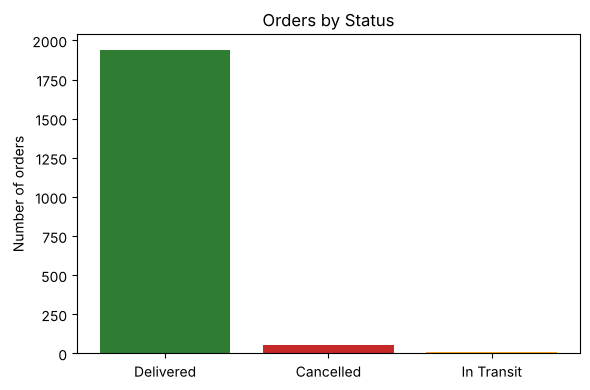

In [12]:
status_counts = df["Order_Status"].value_counts()
print(status_counts)

plt.figure(figsize=(6, 4))
plt.bar(status_counts.index, status_counts.values, color=["#2E7D32", "#C62828", "#F9A825"])
plt.title("Orders by Status")
plt.ylabel("Number of orders")
plt.tight_layout()
plt.savefig("charts/orders_by_status.png", dpi=150)
plt.show()

## Step 8: Average processing time by stage

For each of the six stages we calculate:
- **Average** (mean)
- **Median** (middle value; less affected by a few extreme orders)
- **Slowest 10%** (the 90th percentile: 90% of orders were faster than this)

The `for` loop repeats the same calculation for each stage, so we do not write it six times.

In [13]:
stage_columns = {
    "Receiving": "Receiving_Time_Minutes",
    "Inventory": "Inventory_Check_Time_Minutes",
    "Picking": "Picking_Time_Minutes",
    "Packing": "Packing_Time_Minutes",
    "Dispatch": "Dispatch_Time_Minutes",
    "Delivery": "Delivery_Time_Minutes",
}

delayed_df = df[df["Delay_Status"] == "Delayed"]   # only the delayed orders

rows = []
for stage, column in stage_columns.items():
    rows.append({
        "Stage": stage,
        "Avg_Minutes": df[column].mean(),
        "Median_Minutes": df[column].median(),
        "Slowest_10pct_Minutes": df[column].quantile(0.90),
        "Delays_Caused": (delayed_df["Delay_Stage"] == stage).sum(),
    })

stage_table = pd.DataFrame(rows)
stage_table["Share_of_Delays_pct"] = stage_table["Delays_Caused"] / delayed_orders_count * 100
stage_table.round(1)

,Stage,Avg_Minutes,Median_Minutes,Slowest_10pct_Minutes,Delays_Caused,Share_of_Delays_pct
0,Receiving,7.6,6.0,10.0,3,0.9
1,Inventory,21.4,5.0,10.0,64,19.5
2,Picking,37.4,34.0,56.0,6,1.8
3,Packing,43.7,22.0,104.3,123,37.5
4,Dispatch,42.1,34.0,63.0,50,15.2
5,Delivery,2161.8,2177.0,3302.0,82,25.0


**Chart:** Delivery takes about 36 hours, which is far longer than any warehouse stage, so we leave it out of this chart (courier time is not controlled by the warehouse). The chart compares the five warehouse stages only.

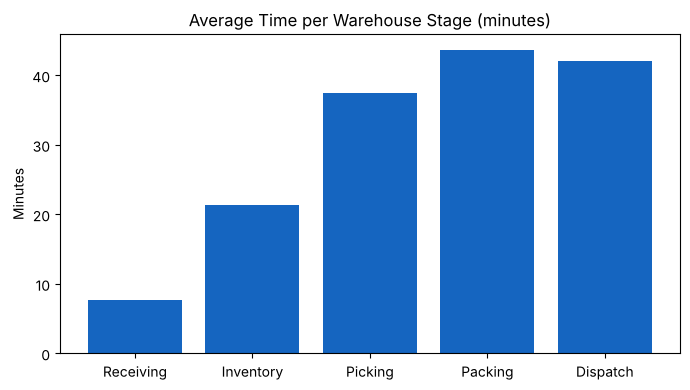

In [14]:
warehouse_stages = stage_table[stage_table["Stage"] != "Delivery"]

plt.figure(figsize=(7, 4))
plt.bar(warehouse_stages["Stage"], warehouse_stages["Avg_Minutes"], color="#1565C0")
plt.title("Average Time per Warehouse Stage (minutes)")
plt.ylabel("Minutes")
plt.tight_layout()
plt.savefig("charts/avg_time_by_stage.png", dpi=150)
plt.show()

## Step 9: Identify delayed orders and the stage with the highest delays

An order is **Delayed** when its total time is longer than the promised time (SLA) for its priority and zone. The column `Delay_Stage` records which stage went furthest over its normal time.

`stage_counts.idxmax()` returns the name of the stage with the largest count.

Delay_Stage
Packing      123
Delivery      82
Inventory     64
Dispatch      50
Picking        6
Receiving      3
Name: count, dtype: int64

Stage with the most delays: Packing -> 123 delays ( 37.5 % of all delays )


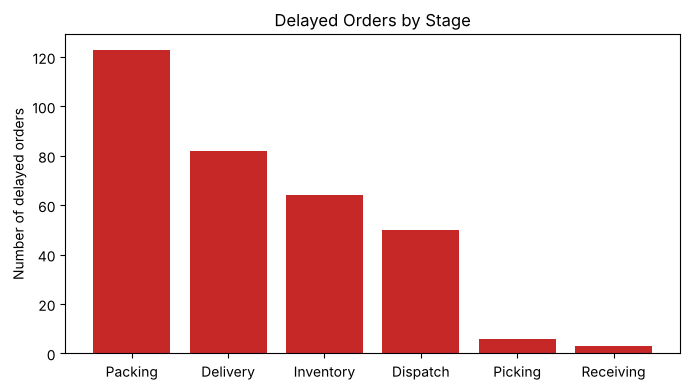

In [15]:
stage_counts = delayed_df["Delay_Stage"].value_counts()
print(stage_counts)
print()

top_stage = stage_counts.idxmax()
top_stage_share = stage_counts.max() / delayed_orders_count * 100
print("Stage with the most delays:", top_stage, "->", stage_counts.max(), "delays (", round(top_stage_share, 1), "% of all delays )")

plt.figure(figsize=(7, 4))
plt.bar(stage_counts.index, stage_counts.values, color="#C62828")
plt.title("Delayed Orders by Stage")
plt.ylabel("Number of delayed orders")
plt.tight_layout()
plt.savefig("charts/delays_by_stage.png", dpi=150)
plt.show()

**Which delays can the warehouse control?** Delivery delays come from the courier. All other stages are inside the warehouse.

In [16]:
warehouse_delays = (delayed_df["Delay_Stage"] != "Delivery").sum()
courier_delays = (delayed_df["Delay_Stage"] == "Delivery").sum()
print("Delays inside the warehouse:", warehouse_delays, "(", round(warehouse_delays / delayed_orders_count * 100, 1), "% )")
print("Delays in courier delivery :", courier_delays, "(", round(courier_delays / delayed_orders_count * 100, 1), "% )")

Delays inside the warehouse: 246 ( 75.0 % )
Delays in courier delivery : 82 ( 25.0 % )


### Why do delays happen? (Delay reasons)

Delay_Reason
Packing station congestion (peak load)    109
Stock-out - awaiting replenishment         64
Courier delay in transit                   62
Courier pickup delay                       36
Dispatch batching wait                     14
Courier route congestion                   14
Packing material shortage                  11
Remote location / address issue             6
Payment/order verification delay            3
Picker shortage during peak shift           3
Understaffed packing shift                  3
Long picking route / poor bin location      3
Name: count, dtype: int64


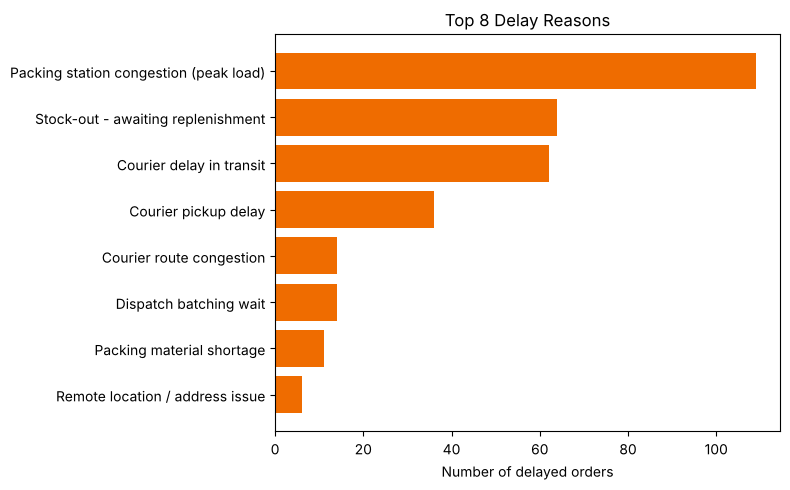

In [17]:
reason_counts = delayed_df["Delay_Reason"].value_counts()
print(reason_counts)

plt.figure(figsize=(8, 5))
top_reasons = reason_counts.head(8).sort_values()     # sorted so the biggest bar is on top
plt.barh(top_reasons.index, top_reasons.values, color="#EF6C00")
plt.title("Top 8 Delay Reasons")
plt.xlabel("Number of delayed orders")
plt.tight_layout()
plt.savefig("charts/delay_reasons.png", dpi=150)
plt.show()

## Step 10: Department-wise performance (summary)

We combine the stage table with how much each stage matters. Printing a sentence from the numbers (instead of typing it ourselves) keeps the conclusion tied to the data.

In [18]:
print(stage_table[["Stage", "Avg_Minutes", "Delays_Caused", "Share_of_Delays_pct"]].sort_values("Delays_Caused", ascending=False).round(1).to_string(index=False))
print()
worst_internal = stage_table[stage_table["Stage"] != "Delivery"].sort_values("Delays_Caused", ascending=False).iloc[0]
print("Warehouse department needing most attention:", worst_internal["Stage"],
      "| delays caused:", int(worst_internal["Delays_Caused"]),
      "| average time:", round(worst_internal["Avg_Minutes"], 1), "minutes")

    Stage  Avg_Minutes  Delays_Caused  Share_of_Delays_pct
  Packing         43.7            123                 37.5
 Delivery       2161.8             82                 25.0
Inventory         21.4             64                 19.5
 Dispatch         42.1             50                 15.2
  Picking         37.4              6                  1.8
Receiving          7.6              3                  0.9

Warehouse department needing most attention: Packing | delays caused: 123 | average time: 43.7 minutes


## Step 11: Digging deeper into the bottleneck

A bottleneck needs an explanation. We test three questions: **When** do delays happen (busy days)? **Who/where** (shifts and employees)? **What** (stock and priority)?

First, a small helper function. A function is a reusable mini-recipe. This one takes a set of orders and returns the percentage that were delayed (ignoring cancelled and in-transit orders).

In [19]:
def delay_rate(data):
    delayed = (data["Delay_Status"] == "Delayed").sum()
    on_time = (data["Delay_Status"] == "On Time").sum()
    return delayed / (delayed + on_time) * 100

### 11a. Busy days: festive sale week (15 to 21 Oct 2026, a hypothetical sale week) versus other days
We convert the date column from text into real dates with `pd.to_datetime`, so we can compare dates.

In [20]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])
is_festive = (df["Order_Date"] >= "2026-10-15") & (df["Order_Date"] <= "2026-10-21")

festive_df = df[is_festive]
normal_df = df[~is_festive]          # the ~ symbol means "NOT"

compare = pd.DataFrame({
    "Festive week": [len(festive_df) / 7, festive_df["Packing_Time_Minutes"].mean(), delay_rate(festive_df)],
    "Other days": [len(normal_df) / 54, normal_df["Packing_Time_Minutes"].mean(), delay_rate(normal_df)],
}, index=["Orders per day", "Average packing time (min)", "Delayed orders (%)"])
compare.round(1)

,Festive week,Other days
Orders per day,65.3,28.6
Average packing time (min),108.9,24.5
Delayed orders (%),37.6,10.8


### 11b. Daily trend of orders and delays
`groupby("Order_Date").size()` counts orders per day. We do the same for delayed orders and line them up by date.

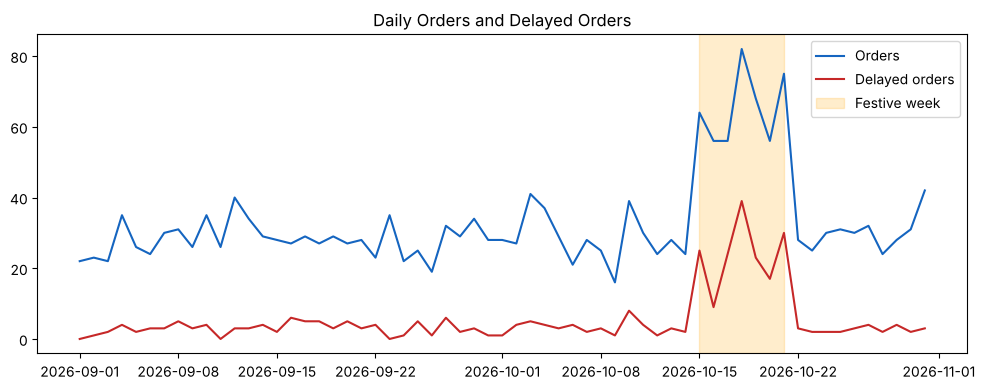

In [21]:
orders_per_day = df.groupby("Order_Date").size()
delays_per_day = df[df["Delay_Status"] == "Delayed"].groupby("Order_Date").size()
delays_per_day = delays_per_day.reindex(orders_per_day.index, fill_value=0)   # days with no delays = 0

plt.figure(figsize=(10, 4))
plt.plot(orders_per_day.index, orders_per_day.values, label="Orders", color="#1565C0")
plt.plot(delays_per_day.index, delays_per_day.values, label="Delayed orders", color="#C62828")
plt.axvspan(pd.Timestamp("2026-10-15"), pd.Timestamp("2026-10-21"), color="orange", alpha=0.2, label="Festive week")
plt.title("Daily Orders and Delayed Orders")
plt.legend()
plt.tight_layout()
plt.savefig("charts/daily_trend.png", dpi=150)
plt.show()

### 11c. Shifts and manpower
We exclude "Unassigned" orders when looking at employees. For each shift we calculate: orders, number of employees, orders per employee, average picking time, average packing time and delay rate.

In [22]:
assigned = df[df["Warehouse_Employee_ID"] != "Unassigned"]

shift_rows = []
for shift in ["Morning", "Evening", "Night"]:
    part = assigned[assigned["Shift"] == shift]
    employees = part["Warehouse_Employee_ID"].nunique()      # nunique = count of different IDs
    shift_rows.append({
        "Shift": shift,
        "Orders": len(part),
        "Employees": employees,
        "Orders_per_Employee": len(part) / employees,
        "Avg_Picking_Min": part["Picking_Time_Minutes"].mean(),
        "Avg_Packing_Min": part["Packing_Time_Minutes"].mean(),
        "Delayed_pct": delay_rate(part),
    })
shift_table = pd.DataFrame(shift_rows)
shift_table.round(1)

,Shift,Orders,Employees,Orders_per_Employee,Avg_Picking_Min,Avg_Packing_Min,Delayed_pct
0,Morning,770,7,110.0,35.8,43.5,18.6
1,Evening,977,7,139.6,38.4,45.2,15.7
2,Night,245,6,40.8,38.6,37.0,15.7


Which employees have the slowest average picking time? (`groupby` collects all orders of each employee; `.mean()` averages them.)

In [23]:
slowest_pickers = assigned.groupby("Warehouse_Employee_ID")["Picking_Time_Minutes"].mean().sort_values(ascending=False)
print(slowest_pickers.head(5).round(1))
print()
print("Average of all other employees:", round(slowest_pickers.iloc[3:].mean(), 1), "minutes")

Warehouse_Employee_ID
EMP012    47.3
EMP018    43.9
EMP005    42.3
EMP016    39.7
EMP013    38.7
Name: Picking_Time_Minutes, dtype: float64

Average of all other employees: 36.5 minutes


### 11d. Inventory shortages by product category
We create a True/False column `Is_Out_of_Stock`. Averaging True/False values gives the share of True (True counts as 1).

Product_Category
Electronics               12.1
Toys & Games              10.5
Fashion & Apparel          8.2
Beauty & Personal Care     8.0
Home & Kitchen             6.5
Sports & Fitness           4.9
Grocery & Gourmet          4.9
Books & Stationery         4.8
Name: Is_Out_of_Stock, dtype: float64


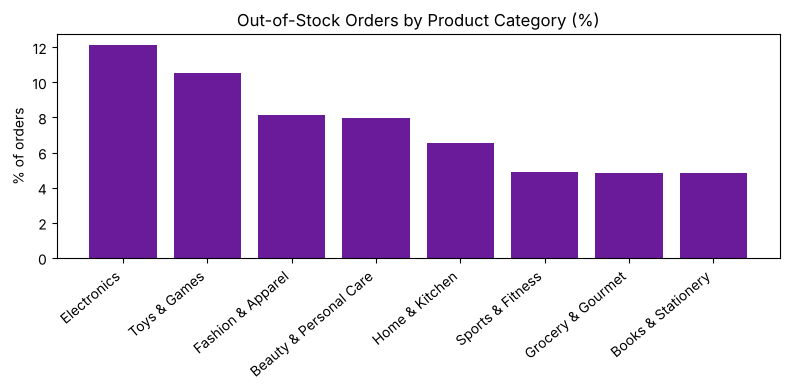

In [24]:
df["Is_Out_of_Stock"] = df["Inventory_Status"] == "Out of Stock"
shortage_by_category = (df.groupby("Product_Category")["Is_Out_of_Stock"].mean() * 100).sort_values(ascending=False)
print(shortage_by_category.round(1))

plt.figure(figsize=(8, 4))
plt.bar(shortage_by_category.index, shortage_by_category.values, color="#6A1B9A")
plt.xticks(rotation=40, ha="right")
plt.title("Out-of-Stock Orders by Product Category (%)")
plt.ylabel("% of orders")
plt.tight_layout()
plt.savefig("charts/shortage_by_category.png", dpi=150)
plt.show()

### 11e. Delay rate by priority and by delivery zone

In [25]:
for priority in ["Express", "Standard", "Economy"]:
    print(priority, "-> delayed:", round(delay_rate(df[df["Order_Priority"] == priority]), 1), "%")
print()
for zone in ["Metro", "Tier-2", "Remote"]:
    print(zone, "-> delayed:", round(delay_rate(df[df["Delivery_Zone"] == zone]), 1), "%")

Express -> delayed: 21.3 %
Standard -> delayed: 17.8 %
Economy -> delayed: 11.0 %

Metro -> delayed: 17.9 %
Tier-2 -> delayed: 14.4 %
Remote -> delayed: 19.5 %


## Step 12: Save the results for the AI assistant and the AI prompts

We pack all calculated numbers into one dictionary and write it to `kpi_summary.json`. The AI will receive only these verified numbers, so it cannot invent statistics.

`float()` and `int()` convert pandas numbers into plain Python numbers, because the json library does not accept pandas types.

In [26]:
summary = {
    "data_note": "SYNTHETIC (hypothetical) warehouse data for an academic project. Not real company data.",
    "period": "2026-09-01 to 2026-10-31",
    "kpis": {
        "total_orders": int(total_orders),
        "completed_orders_delivered": int(completed_orders),
        "cancelled_orders": int(cancelled_orders),
        "in_transit_orders": int(in_transit_orders),
        "delayed_orders": int(delayed_orders_count),
        "on_time_delivery_pct": round(float(on_time_pct), 1),
        "avg_picking_minutes": round(float(avg_picking), 1),
        "avg_packing_minutes": round(float(avg_packing), 1),
        "avg_delivery_hours": round(float(avg_delivery_hours), 1),
        "inventory_shortage_pct": round(float(shortage_pct), 1),
        "total_operational_cost_rs": round(float(total_cost), 2),
    },
    "stages": [
        {
            "stage": row["Stage"],
            "avg_minutes": round(float(row["Avg_Minutes"]), 1),
            "median_minutes": round(float(row["Median_Minutes"]), 1),
            "delays_caused": int(row["Delays_Caused"]),
            "share_of_delays_pct": round(float(row["Share_of_Delays_pct"]), 1),
        }
        for _, row in stage_table.iterrows()
    ],
    "top_delay_stage": top_stage,
    "warehouse_controlled_delays": int(warehouse_delays),
    "courier_delays": int(courier_delays),
    "top_delay_reasons": {reason: int(count) for reason, count in reason_counts.head(8).items()},
    "festive_week_vs_other_days": {
        "festive_orders_per_day": round(float(len(festive_df) / 7), 1),
        "other_orders_per_day": round(float(len(normal_df) / 54), 1),
        "festive_avg_packing_minutes": round(float(festive_df["Packing_Time_Minutes"].mean()), 1),
        "other_avg_packing_minutes": round(float(normal_df["Packing_Time_Minutes"].mean()), 1),
        "festive_delayed_pct": round(float(delay_rate(festive_df)), 1),
        "other_delayed_pct": round(float(delay_rate(normal_df)), 1),
    },
    "shifts": [
        {
            "shift": r["Shift"],
            "orders": int(r["Orders"]),
            "employees": int(r["Employees"]),
            "orders_per_employee": round(float(r["Orders_per_Employee"]), 1),
            "avg_picking_minutes": round(float(r["Avg_Picking_Min"]), 1),
            "avg_packing_minutes": round(float(r["Avg_Packing_Min"]), 1),
            "delayed_pct": round(float(r["Delayed_pct"]), 1),
        }
        for _, r in shift_table.iterrows()
    ],
    "shortage_pct_by_category": {name: round(float(v), 1) for name, v in shortage_by_category.items()},
    "delayed_pct_by_priority": {p: round(float(delay_rate(df[df["Order_Priority"] == p])), 1) for p in ["Express", "Standard", "Economy"]},
    "delayed_pct_by_zone": {z: round(float(delay_rate(df[df["Delivery_Zone"] == z])), 1) for z in ["Metro", "Tier-2", "Remote"]},
}

with open("kpi_summary.json", "w") as file:
    json.dump(summary, file, indent=2)

print("Saved kpi_summary.json")
print("Top delay stage in file:", summary["top_delay_stage"])

Saved kpi_summary.json
Top delay stage in file: Packing


## Step 13: Summary of findings (generated from the numbers above)

In [27]:
print("Total orders:", total_orders, "| Delivered:", completed_orders, "| Delayed:", delayed_orders_count, "| On-time %:", round(on_time_pct, 1))
print("Stage with most delays:", top_stage, "(", round(top_stage_share, 1), "% of delays )")
print("Delays inside warehouse:", round(warehouse_delays / delayed_orders_count * 100, 1), "% | courier:", round(courier_delays / delayed_orders_count * 100, 1), "%")
print("Delay rate festive week:", round(delay_rate(festive_df), 1), "% vs other days:", round(delay_rate(normal_df), 1), "%")
print("Charts saved in the charts folder; numbers saved in kpi_summary.json")

Total orders: 2000 | Delivered: 1941 | Delayed: 328 | On-time %: 83.1
Stage with most delays: Packing ( 37.5 % of delays )
Delays inside warehouse: 75.0 % | courier: 25.0 %
Delay rate festive week: 37.6 % vs other days: 10.8 %
Charts saved in the charts folder; numbers saved in kpi_summary.json


### Important reminder for the viva
The dataset is synthetic and we built certain causes (such as packing queues on busy days) into the data generator. So this analysis shows that **our method can find a bottleneck**. It does not prove those causes exist in real warehouses.

### What each team member should be able to explain
- **Everyone:** why some blank cells are normal, why we remove duplicates, how On-Time % is calculated.
- **Data analyst:** each cleaning rule and why.
- **BI analyst:** which of these numbers become Power BI KPIs and DAX measures.
- **GenAI developer:** why `kpi_summary.json` is fed to the AI.
- **Automation lead:** how the same calculations are repeated inside n8n.